# Day.2 Pandas - 데이터 정리하기

In [2]:
# ===== 공통 설정 (모든 노트북 첫 셀) =====
import platform
import matplotlib.pyplot as plt
from matplotlib import font_manager
import pandas as pd

# 1) 그래프 한글 폰트
if platform.system() == 'Windows':
    FONT_NAME = 'Malgun Gothic'      # 맑은 고딕
elif platform.system() == 'Darwin':  # Mac
    FONT_NAME = 'AppleGothic'
else:
    FONT_NAME = 'NanumGothic'
plt.rc('font', family=FONT_NAME)
plt.rcParams['axes.unicode_minus'] = False   # 마이너스(-) 깨짐 방지

# 2) 워드클라우드용 폰트 파일 경로 (6장에서 사용)
FONT_PATH = font_manager.findfont(FONT_NAME)

# 3) 표 출력 옵션
pd.set_option('display.unicode.east_asian_width', True)  # 한글 표 줄맞춤
pd.set_option('display.max_columns', None)               # 열 생략(...) 없이 보기
pd.set_option('display.width', 200)

print('설정 완료 | 폰트:', FONT_NAME)

설정 완료 | 폰트: Malgun Gothic


In [3]:
from pathlib import Path

if not Path('data/cafe_sales.csv').exists():
    Path('data').mkdir(exist_ok=True)
    csv_text = """날짜,지점,메뉴,분류,가격,수량,날씨
2026-11-02,강남점,아메리카노,커피,4500,32,맑음
2026-11-02,강남점,카페라테,커피,5000,18,맑음
2026-11-02,강남점,치즈케이크,디저트,6500,7,맑음
2026-11-02,홍대점,아메리카노,커피,4300,41,맑음
2026-11-02,홍대점,자몽에이드,음료,5800,12,맑음
2026-11-03,강남점,아메리카노,커피,4500,28,흐림
2026-11-03,강남점,카페라테,커피,5000,,흐림
2026-11-03,홍대점,카페라테,커피,4800,22,흐림
2026-11-03,홍대점,치즈케이크,디저트,6300,9,흐림
2026-11-03,홍대점,자몽에이드,음료,5800,8,흐림
2026-11-04,강남점,아메리카노,커피,4500,25,비
2026-11-04,강남점,치즈케이크,디저트,6500,11,비
2026-11-04,강남점,자몽에이드,음료,6000,4,비
2026-11-04,홍대점,아메리카노,커피,4300,30,비
2026-11-04,홍대점,카페라테,커피,4800,26,
2026-11-05,강남점,아메리카노,커피,4500,35,맑음
2026-11-05,강남점,카페라테,커피,5000,21,맑음
2026-11-05,홍대점,아메리카노,커피,4300,44,맑음
2026-11-05,홍대점,치즈케이크,디저트,6300,13,맑음
2026-11-05,홍대점,자몽에이드,음료,5800,15,맑음
"""
    Path('data/cafe_sales.csv').write_text(csv_text, encoding='utf-8')
    print('파일 생성 완료')
else:
    print('이미 파일이 있습니다')

이미 파일이 있습니다


# 결측치 찾기

In [13]:
import os
print(os.listdir(r'C:\workspace1\src\workspace1'))

['data', 'day1.ipynb', 'day2.ipynb', 'thunder.png', 'wordcloud.png', '__init__.py', '제목 없음.png']


In [ ]:
import pandas as pd
df = pd.read_csv('./data/cafe_sales.csv', thousands=',', encoding='utf-8')

In [12]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 7 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   날짜    20 non-null     str    
 1   지점    20 non-null     str    
 2   메뉴    20 non-null     str    
 3   분류    20 non-null     str    
 4   가격    20 non-null     int64  
 5   수량    19 non-null     float64
 6   날씨    19 non-null     str    
dtypes: float64(1), int64(1), str(5)
memory usage: 1.2 KB


In [14]:
df.isna().sum()

날짜    0
지점    0
메뉴    0
분류    0
가격    0
수량    1
날씨    1
dtype: int64

In [15]:
avg = df['수량'].mean()
df['수량'] = df['수량'].fillna(avg)
df['수량'] = df['수량'].round().astype(int)


In [16]:
df

,날짜,지점,메뉴,분류,가격,수량,날씨
0,2026-11-02,강남점,아메리카노,커피,4500,32,맑음
1,2026-11-02,강남점,카페라테,커피,5000,18,맑음
2,2026-11-02,강남점,치즈케이크,디저트,6500,7,맑음
3,2026-11-02,홍대점,아메리카노,커피,4300,41,맑음
4,2026-11-02,홍대점,자몽에이드,음료,5800,12,맑음
5,2026-11-03,강남점,아메리카노,커피,4500,28,흐림
6,2026-11-03,강남점,카페라테,커피,5000,21,흐림
7,2026-11-03,홍대점,카페라테,커피,4800,22,흐림
8,2026-11-03,홍대점,치즈케이크,디저트,6300,9,흐림
9,2026-11-03,홍대점,자몽에이드,음료,5800,8,흐림


In [19]:
df['날씨'] = df['날씨'].fillna('미상')

In [20]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 7 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   날짜    20 non-null     str  
 1   지점    20 non-null     str  
 2   메뉴    20 non-null     str  
 3   분류    20 non-null     str  
 4   가격    20 non-null     int64
 5   수량    20 non-null     int64
 6   날씨    20 non-null     str  
dtypes: int64(2), str(5)
memory usage: 1.2 KB


In [23]:
df['매출'] = df['가격'] * df['수량']
df[['메뉴', '매출', '가격', '수량']]

,메뉴,매출,가격,수량
0,아메리카노,144000,4500,32
1,카페라테,90000,5000,18
2,치즈케이크,45500,6500,7
3,아메리카노,176300,4300,41
4,자몽에이드,69600,5800,12
5,아메리카노,126000,4500,28
6,카페라테,105000,5000,21
7,카페라테,105600,4800,22
8,치즈케이크,56700,6300,9
9,자몽에이드,46400,5800,8


In [39]:
import numpy as np
df['판매등급'] = np.where(df['판매수량'] >= 30, '인기', '보통')
df[['메뉴', '판매수량', '판매등급']]

,메뉴,판매수량,판매등급
0,아메리카노,32,인기
1,카페라테,18,보통
2,치즈케이크,7,보통
3,아메리카노,41,인기
4,자몽에이드,12,보통
5,아메리카노,28,보통
6,카페라테,21,보통
7,카페라테,22,보통
8,치즈케이크,9,보통
9,자몽에이드,8,보통


In [25]:
df['날짜'] = pd.to_datetime(df['날짜'])
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 9 columns):
 #   Column    Non-Null Count  Dtype         
---  ------    --------------  -----         
 0   날짜      20 non-null     datetime64[us]
 1   지점      20 non-null     str           
 2   메뉴      20 non-null     str           
 3   분류      20 non-null     str           
 4   가격      20 non-null     int64         
 5   수량      20 non-null     int64         
 6   날씨      20 non-null     str           
 7   매출      20 non-null     int64         
 8   판매등급  20 non-null     str           
dtypes: datetime64[us](1), int64(3), str(5)
memory usage: 1.5 KB


In [28]:
print(df['날짜'].dt.year.head(1))
print(df['날짜'].dt.month.head(1))
print(df['날짜'].dt.day.head(1))

0    2026
Name: 날짜, dtype: int32
0    11
Name: 날짜, dtype: int32
0    2
Name: 날짜, dtype: int32


In [35]:
df_03_05 = df[(df['날짜'] >= '2026-11-03') & (df['날짜'] <= '2026-11-05')]
df_03_05[['날짜', '지점', '메뉴', '매출']]

,날짜,지점,메뉴,매출
5,2026-11-03,강남점,아메리카노,126000
6,2026-11-03,강남점,카페라테,105000
7,2026-11-03,홍대점,카페라테,105600
8,2026-11-03,홍대점,치즈케이크,56700
9,2026-11-03,홍대점,자몽에이드,46400
10,2026-11-04,강남점,아메리카노,112500
11,2026-11-04,강남점,치즈케이크,71500
12,2026-11-04,강남점,자몽에이드,24000
13,2026-11-04,홍대점,아메리카노,129000
14,2026-11-04,홍대점,카페라테,124800


In [40]:
#수량 -> 판매수량
df = df.rename(columns={'수량': '판매수량'})
df.columns

Index(['날짜', '지점', '메뉴', '분류', '가격', '판매수량', '날씨', '매출', '판매등급'], dtype='str')

In [37]:
#Column 삭제
df = df.drop(columns=['판매등급'])
df.columns

Index(['날짜', '지점', '메뉴', '분류', '가격', '판매수량', '날씨', '매출'], dtype='str')

In [41]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 9 columns):
 #   Column    Non-Null Count  Dtype         
---  ------    --------------  -----         
 0   날짜      20 non-null     datetime64[us]
 1   지점      20 non-null     str           
 2   메뉴      20 non-null     str           
 3   분류      20 non-null     str           
 4   가격      20 non-null     int64         
 5   판매수량  20 non-null     int64         
 6   날씨      20 non-null     str           
 7   매출      20 non-null     int64         
 8   판매등급  20 non-null     str           
dtypes: datetime64[us](1), int64(3), str(5)
memory usage: 1.5 KB


In [57]:
df.to_csv('./data/cafe_sales_clean.csv', encoding='utf-8', index=False)

In [56]:
new_df = pd.read_csv('data/cafe_sales_clean.csv',
                     parse_dates=['날짜'],
                     thousands=',')

In [44]:
print(new_df)

         날짜    지점        메뉴    분류  가격  판매수량  날씨    매출 판매등급
0  2026-11-02  강남점  아메리카노    커피  4500        32  맑음  144000     인기
1  2026-11-02  강남점    카페라테    커피  5000        18  맑음   90000     보통
2  2026-11-02  강남점  치즈케이크  디저트  6500         7  맑음   45500     보통
3  2026-11-02  홍대점  아메리카노    커피  4300        41  맑음  176300     인기
4  2026-11-02  홍대점  자몽에이드    음료  5800        12  맑음   69600     보통
5  2026-11-03  강남점  아메리카노    커피  4500        28  흐림  126000     보통
6  2026-11-03  강남점    카페라테    커피  5000        21  흐림  105000     보통
7  2026-11-03  홍대점    카페라테    커피  4800        22  흐림  105600     보통
8  2026-11-03  홍대점  치즈케이크  디저트  6300         9  흐림   56700     보통
9  2026-11-03  홍대점  자몽에이드    음료  5800         8  흐림   46400     보통
10 2026-11-04  강남점  아메리카노    커피  4500        25    비  112500     보통
11 2026-11-04  강남점  치즈케이크  디저트  6500        11    비   71500     보통
12 2026-11-04  강남점  자몽에이드    음료  6000         4    비   24000     보통
13 2026-11-04  홍대점  아메리카노    커피  4300        30    비  129000     인기

In [63]:
import pandas as pd
df = pd.read_csv('./data/cafe_sales.csv')

**문제 1.** `수량`과 `날씨` 열에 빈칸이 각각 몇 개인지 출력하세요.

In [64]:
# 여기에 코드를 작성하세요
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 7 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   날짜    20 non-null     str    
 1   지점    20 non-null     str    
 2   메뉴    20 non-null     str    
 3   분류    20 non-null     str    
 4   가격    20 non-null     int64  
 5   수량    19 non-null     float64
 6   날씨    19 non-null     str    
dtypes: float64(1), int64(1), str(5)
memory usage: 1.2 KB


수량 1개, 날씨 1개

**문제 2.** 날씨 빈칸은 '맑음'으로, 수량 빈칸은 0으로 채우고, 수량을 정수로 바꾸세요. 그다음 가격을 10% 할인한 `할인가` 열(정수)을 만들어 `메뉴`, `가격`, `할인가`, `날씨` 앞 3줄을 보여 주세요.

In [65]:
# 여기에 코드를 작성하세요
df['날씨'] = df['날씨'].fillna("맑음")
df['수량'] = df['수량'].fillna(0).astype(int)

In [66]:
df['할인가'] = (df['가격'] * 0.9).astype(int)
df[['메뉴', '가격', '할인가', '날씨']].head(3)

,메뉴,가격,할인가,날씨
0,아메리카노,4500,4050,맑음
1,카페라테,5000,4500,맑음
2,치즈케이크,6500,5850,맑음


**문제 3.** (문제 2에 이어서) `매출` 열을 만들고, 매출이 가장 큰 기록 3개의 `날짜`, `지점`, `메뉴`, `매출`을 보여 주세요.

In [69]:
# 여기에 코드를 작성하세요
df['메뉴 당 판매액'] = (df['가격'] * df['수량']).astype(int)
df[['날짜', '지점', '메뉴', '메뉴 당 판매액']]

,날짜,지점,메뉴,메뉴 당 판매액
0,2026-11-02,강남점,아메리카노,144000
1,2026-11-02,강남점,카페라테,90000
2,2026-11-02,강남점,치즈케이크,45500
3,2026-11-02,홍대점,아메리카노,176300
4,2026-11-02,홍대점,자몽에이드,69600
5,2026-11-03,강남점,아메리카노,126000
6,2026-11-03,강남점,카페라테,0
7,2026-11-03,홍대점,카페라테,105600
8,2026-11-03,홍대점,치즈케이크,56700
9,2026-11-03,홍대점,자몽에이드,46400


**문제 4.** 가격이 5,000원 이상이면 '고가', 아니면 '저가'인 `가격대` 열을 만들고 개수를 세어 보세요.

In [70]:
# 여기에 코드를 작성하세요
import ntpath
df['가격대'] = np.where(df['가격']>=5000, '고가', '저가')
df['가격대'].value_counts()

가격대
고가    11
저가     9
Name: count, dtype: int64

**문제 5.** 날짜를 날짜형으로 바꾸고, `'11/02'` 형태의 `월일` 열을 만든 뒤 서로 다른 값만 출력하세요.

In [ ]:
df['날짜'] = pd.to_datetime(df['날짜'])


0    2026-11-02
1    2026-11-02
2    2026-11-02
3    2026-11-02
4    2026-11-02
5    2026-11-03
6    2026-11-03
7    2026-11-03
8    2026-11-03
9    2026-11-03
10   2026-11-04
11   2026-11-04
12   2026-11-04
13   2026-11-04
14   2026-11-04
15   2026-11-05
16   2026-11-05
17   2026-11-05
18   2026-11-05
19   2026-11-05
Name: 날짜, dtype: datetime64[us]

In [92]:
# 여기에 코드를 작성하세요
df['날짜'] = pd.to_datetime(df['날짜'])
df['월일'] = df['날짜'].dt.strftime('%m/%d')
df['월일'].unique()

<StringArray>
['11/02', '11/03', '11/04', '11/05']
Length: 4, dtype: str

**문제 6. (생각해 보기)** 아래 코드를 실행했는데 수량의 빈칸이 그대로 남아 있습니다. 이유와 고친 코드를 쓰세요.
```python
df['수량'].fillna(0, inplace=True)
```

In [93]:
#변경 전
df['수량']

0     32
1     18
2      7
3     41
4     12
5     28
6      0
7     22
8      9
9      8
10    25
11    11
12     4
13    30
14    26
15    35
16    21
17    44
18    13
19    15
Name: 수량, dtype: int64

In [94]:
#변경 후 
df['수량'].fillna(0, inplace=True)
df['수량']

C:\Users\Admin\AppData\Local\Temp\ipykernel_4228\1415934960.py:2: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/docs/dev/user_guide/migration.html#copy-on-write-cow
  df['수량'].fillna(0, inplace=True)


0     32
1     18
2      7
3     41
4     12
5     28
6      0
7     22
8      9
9      8
10    25
11    11
12     4
13    30
14    26
15    35
16    21
17    44
18    13
19    15
Name: 수량, dtype: int64

**답:** (이유와 고친 코드를 여기에 작성하세요)

In [95]:
# 고친 코드를 실행해서 확인해 보세요
df['수량'] = df['수량'].fillna(0)
df['수량']

0     32
1     18
2      7
3     41
4     12
5     28
6      0
7     22
8      9
9      8
10    25
11    11
12     4
13    30
14    26
15    35
16    21
17    44
18    13
19    15
Name: 수량, dtype: int64

**문제 7. (생각해 보기)** 아래 코드를 실행했더니 `IntCastingNaNError` 오류가 났습니다. 무엇을 먼저 해야 할까요?
```python
d['수량'] = d['수량'].astype(int)
```

**답:** (여기에 작성하세요) NaN 값이 있어서 fillna 후 실행

# 3_pandas 실습

In [109]:
from pathlib import Path

if not Path('data/cafe_sales_clean.csv').exists():
    Path('data').mkdir(exist_ok=True)
    csv_text = """날짜,지점,메뉴,분류,가격,판매수량,날씨,매출,판매등급,요일
2026-11-02,강남점,아메리카노,커피,4500,32,맑음,144000,인기,월
2026-11-02,강남점,카페라테,커피,5000,18,맑음,90000,보통,월
2026-11-02,강남점,치즈케이크,디저트,6500,7,맑음,45500,보통,월
2026-11-02,홍대점,아메리카노,커피,4300,41,맑음,176300,인기,월
2026-11-02,홍대점,자몽에이드,음료,5800,12,맑음,69600,보통,월
2026-11-03,강남점,아메리카노,커피,4500,28,흐림,126000,보통,화
2026-11-03,강남점,카페라테,커피,5000,21,흐림,105000,보통,화
2026-11-03,홍대점,카페라테,커피,4800,22,흐림,105600,보통,화
2026-11-03,홍대점,치즈케이크,디저트,6300,9,흐림,56700,보통,화
2026-11-03,홍대점,자몽에이드,음료,5800,8,흐림,46400,보통,화
2026-11-04,강남점,아메리카노,커피,4500,25,비,112500,보통,수
2026-11-04,강남점,치즈케이크,디저트,6500,11,비,71500,보통,수
2026-11-04,강남점,자몽에이드,음료,6000,4,비,24000,보통,수
2026-11-04,홍대점,아메리카노,커피,4300,30,비,129000,인기,수
2026-11-04,홍대점,카페라테,커피,4800,26,비,124800,보통,수
2026-11-05,강남점,아메리카노,커피,4500,35,맑음,157500,인기,목
2026-11-05,강남점,카페라테,커피,5000,21,맑음,105000,보통,목
2026-11-05,홍대점,아메리카노,커피,4300,44,맑음,189200,인기,목
2026-11-05,홍대점,치즈케이크,디저트,6300,13,맑음,81900,보통,목
2026-11-05,홍대점,자몽에이드,음료,5800,15,맑음,87000,보통,목
"""
    Path('data/cafe_sales_clean.csv').write_text(csv_text, encoding='utf-8-sig')
    print('파일 생성 완료')
else:
    print('이미 파일이 있습니다')

파일 생성 완료


In [110]:
import pandas as pd
import numpy as np

df = pd.read_csv('data/cafe_sales_clean.csv')

## 집계란?

In [111]:
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
날짜,20,4,2026-11-02,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN
지점,20,2,강남점,10,NaN,NaN,NaN,NaN,NaN,NaN,NaN
메뉴,20,4,아메리카노,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN
분류,20,3,커피,12,NaN,NaN,NaN,NaN,NaN,NaN,NaN
가격,20.0,NaN,NaN,NaN,5225.0,805.817663,4300.0,4500.0,5000.0,5850.0,6500.0
판매수량,20.0,NaN,NaN,NaN,21.1,11.484085,4.0,11.75,21.0,28.5,44.0
날씨,20,3,맑음,10,NaN,NaN,NaN,NaN,NaN,NaN,NaN
매출,20.0,NaN,NaN,NaN,102375.0,44191.293201,24000.0,71025.0,105000.0,126750.0,189200.0
판매등급,20,2,보통,15,NaN,NaN,NaN,NaN,NaN,NaN,NaN
요일,20,4,월,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [117]:
df.groupby(['지점', '분류'])['매출'].sum().reset_index()

,지점,분류,매출
0,강남점,디저트,117000
1,강남점,음료,24000
2,강남점,커피,840000
3,홍대점,디저트,138600
4,홍대점,음료,203000
5,홍대점,커피,724900


In [119]:
df.groupby('날씨')['판매수량'].sum()

날씨
맑음    238
비       96
흐림     88
Name: 판매수량, dtype: int64

In [121]:
#요일, 메뉴, 판매수량, sum
df8 = pd.pivot_table(
    df,
    index = "요일",
    columns = "메뉴",
    values = "판매수량",
    aggfunc = 'sum',
    fill_value = 0
)
df8.reindex(['월', '화', '수', '목'])
df8

메뉴,아메리카노,자몽에이드,치즈케이크,카페라테
요일,,,,
목,79,15,13,21
수,55,4,11,26
월,73,12,7,18
화,28,8,9,43


In [123]:
# 지점, 분류, 매출, sum
new_df = pd.pivot_table(
    df,
    index = '지점',
    columns = '분류',
    values = '매출',
    aggfunc= 'sum',
    fill_value = 0,
    margins=True,
    margins_name="합계",
)
new_df

분류,디저트,음료,커피,합계
지점,,,,
강남점,117000,24000,840000,981000
홍대점,138600,203000,724900,1066500
합계,255600,227000,1564900,2047500


In [124]:
new = pd.DataFrame({'날짜': pd.to_datetime(['2026-11-06', '2026-11-06']),
                    '지점': ['강남점', '홍대점'],
                    '메뉴': ['아메리카노', '아메리카노'],
                    '분류': ['커피', '커피'],
                    '가격': [4500, 4300],
                    '판매수량': [30, 38],
                    '날씨': ['맑음', '맑음']})

new['매출'] = new['가격'] * new['판매수량']

all_df = pd.concat([df, new], ignore_index=True)

print(df.shape, new.shape, all_df.shape)
all_df.tail(3)

(20, 10) (2, 8) (22, 10)


,날짜,지점,메뉴,분류,가격,판매수량,날씨,매출,판매등급,요일
19,2026-11-05,홍대점,자몽에이드,음료,5800,15,맑음,87000,보통,목
20,2026-11-06 00:00:00,강남점,아메리카노,커피,4500,30,맑음,135000,NaN,NaN
21,2026-11-06 00:00:00,홍대점,아메리카노,커피,4300,38,맑음,163400,NaN,NaN


In [125]:
all_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 22 entries, 0 to 21
Data columns (total 10 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   날짜      22 non-null     object
 1   지점      22 non-null     str   
 2   메뉴      22 non-null     str   
 3   분류      22 non-null     str   
 4   가격      22 non-null     int64 
 5   판매수량  22 non-null     int64 
 6   날씨      22 non-null     str   
 7   매출      22 non-null     int64 
 8   판매등급  20 non-null     str   
 9   요일      20 non-null     str   
dtypes: int64(3), object(1), str(6)
memory usage: 1.8+ KB


In [126]:
menu = pd.DataFrame({'메뉴': ['아메리카노', '카페라테', '치즈케이크', '자몽에이드'],
                     '원가': [1200, 1800, 3000, 2200]})

m = pd.merge(df, menu, on='메뉴', how='left')

m['이익'] = (m['가격'] - m['원가']) * m['판매수량']

m[['지점', '메뉴', '가격', '원가', '판매수량', '이익']].head(4)

,지점,메뉴,가격,원가,판매수량,이익
0,강남점,아메리카노,4500,1200,32,105600
1,강남점,카페라테,5000,1800,18,57600
2,강남점,치즈케이크,6500,3000,7,24500
3,홍대점,아메리카노,4300,1200,41,127100


In [127]:
메뉴요약 = df.groupby('메뉴').agg(총수량=('판매수량', 'sum'),
                              총매출=('매출', 'sum'),
                              평균가격=('가격', 'mean'),
                              기록수=('메뉴', 'count'))
메뉴요약

,총수량,총매출,평균가격,기록수
메뉴,,,,
아메리카노,235,1034500,4414.285714,7
자몽에이드,39,227000,5850.000000,4
치즈케이크,40,255600,6400.000000,4
카페라테,108,530400,4920.000000,5


In [128]:
m.groupby('메뉴')['이익'].sum().sort_values(ascending=False)

메뉴
아메리카노    752500
카페라테      336000
자몽에이드    141200
치즈케이크    135600
Name: 이익, dtype: int64

In [ ]:
m.groupby('메뉴')['이익'].

In [131]:
원가율 = m.groupby('메뉴').agg(
                          평균가격=('가격', 'mean'),
                          원가=('원가', 'first'))
원가율['원가율(%)'] = (원가율['원가'] / 원가율['평균가격'] * 100).round(1)
원가율.sort_values('원가율(%)', ascending=False)


,평균가격,원가,원가율(%)
메뉴,,,
치즈케이크,6400.000000,3000,46.9
자몽에이드,5850.000000,2200,37.6
카페라테,4920.000000,1800,36.6
아메리카노,4414.285714,1200,27.2


In [133]:
m.to_csv('./data/problem.csv', encoding='utf-8')

In [ ]:
import pandas as pd

df = pd.read_csv("problem.csv", index_col=0)    

**문제 1.** 요일별 매출 합계를 월·화·수·목 순서로 보여 주세요.

In [134]:
# 여기에 코드를 작성하세요
df.groupby("요일")["매출"].sum().reindex(["월", "화", "수", "목"])

요일
월    525400
화    439700
수    461800
목    620600
Name: 매출, dtype: int64

**문제 2.** 분류별 판매 수량 합계를 많은 순서로 보여 주세요.

In [135]:
# 여기에 코드를 작성하세요
df.groupby("분류")["판매수량"].sum().sort_values(ascending=False)

분류
커피      343
디저트     40
음료       39
Name: 판매수량, dtype: int64

**문제 3.** 지점 × 메뉴 조합별 판매 수량 합계를 구하고, 가장 많이 팔린 조합 3개를 보여 주세요.

In [136]:
# 여기에 코드를 작성하세요
df.groupby(["지점", "메뉴"])["판매수량"].sum().sort_values(ascending=False).head(3)

지점    메뉴 
강남점  아메리카노    120
홍대점  아메리카노    115
강남점  카페라테       60
Name: 판매수량, dtype: int64

**문제 4.** 날씨(행) × 지점(열)로 평균 판매 수량 교차표를 만들고, 소수점 첫째 자리까지 반올림하세요.

In [137]:
# 여기에 코드를 작성하세요
df.pivot_table(
    index="날씨",
    columns="지점",
    values="판매수량",
    aggfunc="mean"
).round(1)

지점,강남점,홍대점
날씨,,
맑음,22.6,25.0
비,13.3,28.0
흐림,24.5,13.0


**문제 5.** 본문에서 만든 `m`(원가 연결 표)으로 지점별 이익 합계를 구해 보세요.

In [138]:
# 여기에 코드를 작성하세요
m.groupby("지점")["이익"].sum()

지점
강남점    666200
홍대점    699100
Name: 이익, dtype: int64

# 데이터 시각화

## matplotlib

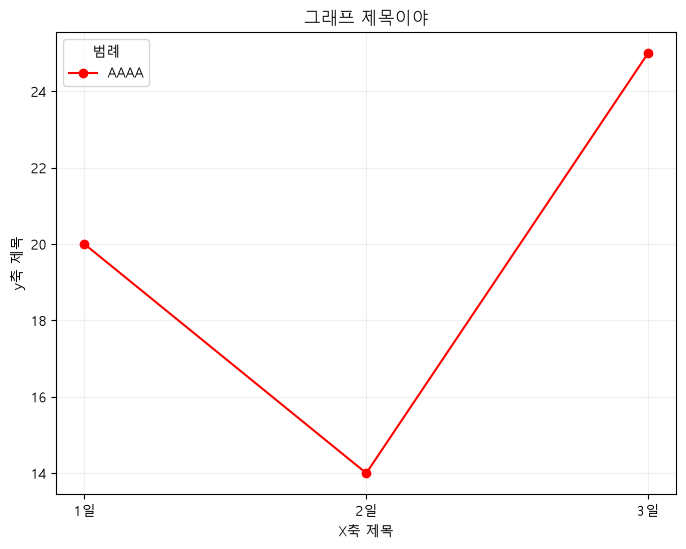

In [151]:
# 축(x, y) x데이터, y데이터
import matplotlib.pyplot as plt

x = [1, 2, 3]
y = [20, 14, 25]

plt.figure(figsize=(8, 6))
plt.plot(x, y, marker='o', color='red', label='AAAA')
plt.title('그래프 제목이야')
plt.xlabel('X축 제목')
plt.ylabel('y축 제목')
plt.legend(title='범례')
plt.xticks(x, ['1일', '2일', '3일'])
plt.yticks()
plt.grid(alpha=0.2)
plt.show()


In [153]:
df.groupby('메뉴')['판매수량'].sum()

메뉴
아메리카노    235
자몽에이드     39
치즈케이크     40
카페라테      108
Name: 판매수량, dtype: int64

In [175]:
type(value_df.index.to_list())

list

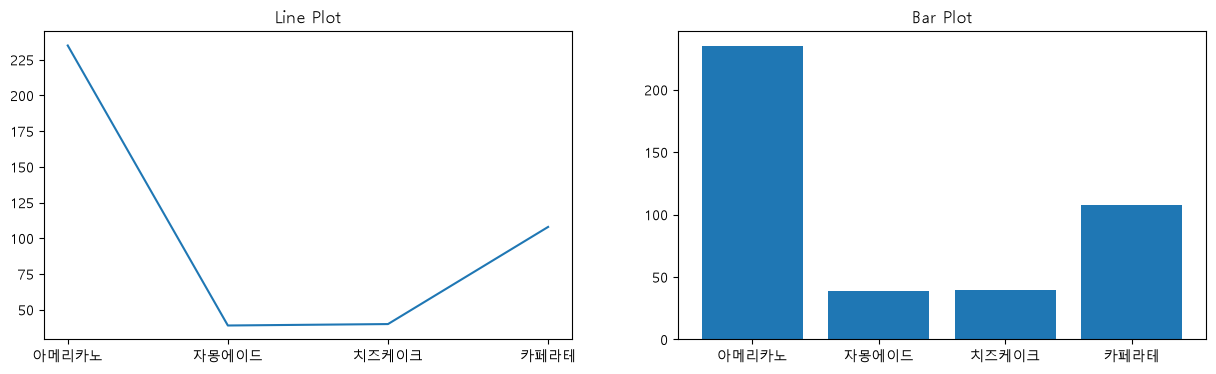

In [174]:
value_df = df.groupby('메뉴')['판매수량'].sum()
x = [menu for menu in value_df.index]
y = [value for value in value_df.values]

fig, ax = plt.subplots(1, 2, figsize=(15,4))
ax[0].plot(value_df.index,y)
ax[0].set_title('Line Plot')
ax[1].bar(x,y)
ax[1].set_title('Bar Plot')
plt.show()



In [180]:
day_df = df.groupby('날짜')['매출'].sum()

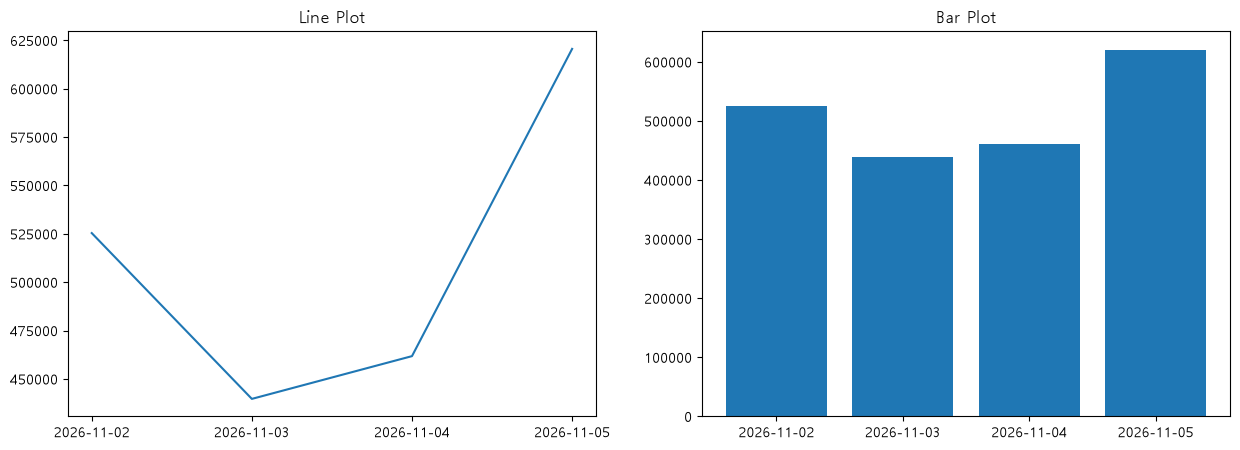

In [179]:
# lineplot -> 변화의 추세(시간, 날짜)
# 날짜별 매출의 합계
day_df = df.groupby('날짜')['매출'].sum()
x = day_df.index
y = day_df.values
fig, ax = plt.subplots(1, 2, figsize=(15,5))
ax[0].plot(x,y)
ax[0].set_title('Line Plot')
ax[1].bar(x,y)
ax[1].set_title('Bar Plot')
plt.show()

In [187]:
date_place_df = df.pivot_table(
    index = '날짜',
    columns= '지점',
    values= '매출',
    aggfunc= 'sum',
    fill_value= 0,    
).round(1)

In [192]:
print(date_place_df.index)
print(date_place_df['강남점'])
print(date_place_df['홍대점'])

Index(['2026-11-02', '2026-11-03', '2026-11-04', '2026-11-05'], dtype='str', name='날짜')
날짜
2026-11-02    279500
2026-11-03    231000
2026-11-04    208000
2026-11-05    262500
Name: 강남점, dtype: int64
날짜
2026-11-02    245900
2026-11-03    208700
2026-11-04    253800
2026-11-05    358100
Name: 홍대점, dtype: int64


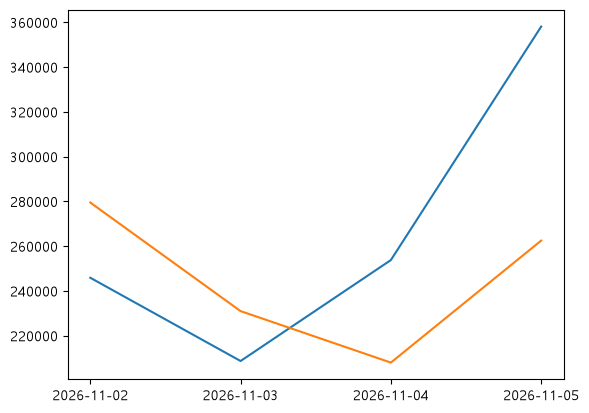

In [ ]:
hong = date_place_df['홍대점']
gang = date_place_df['강남점']
plt.plot(x, hong)
plt.plot(x, gang)
plt.show()

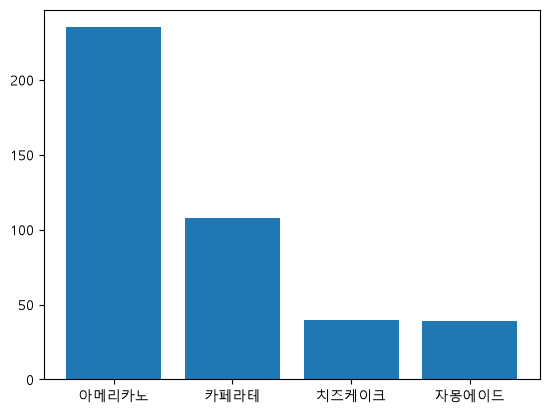

In [196]:
value_df = df.groupby('메뉴')['판매수량'].sum().sort_values(ascending=False)
x = [menu for menu in value_df.index]
y = [value for value in value_df.values]
plt.bar(x,y)
plt.show()


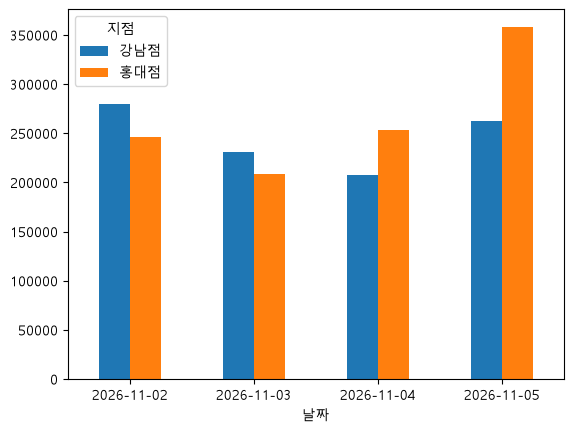

In [197]:
df7 = pd.pivot_table(
    df,
    index='날짜',
    columns='지점',
    values='매출',
    aggfunc='sum'
)
df7.plot(kind='bar', rot=0)
plt.show()

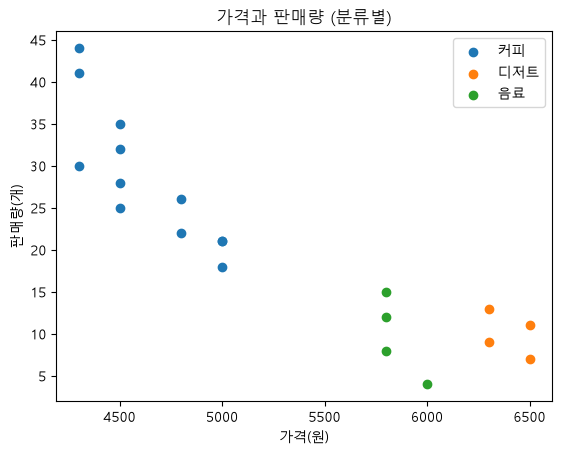

In [200]:
for cat in df['분류'].unique():
    sub = df[df['분류'] == cat]
    plt.scatter(sub['가격'], sub['판매수량'], label=cat)
plt.title('가격과 판매량 (분류별)')
plt.xlabel('가격(원)')
plt.ylabel('판매량(개)')
plt.legend()
plt.show()

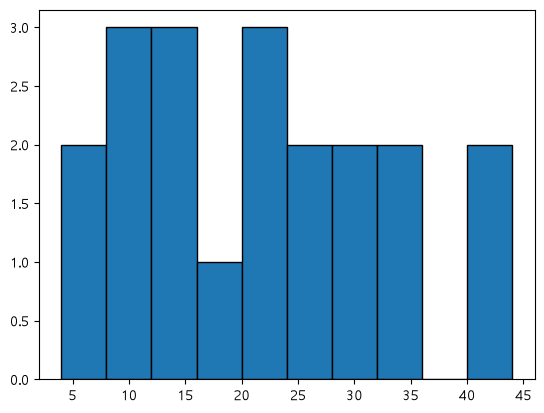

In [201]:
plt.hist(df['판매수량'], bins=10, edgecolor='black')
plt.show()

<Axes: xlabel='분류'>

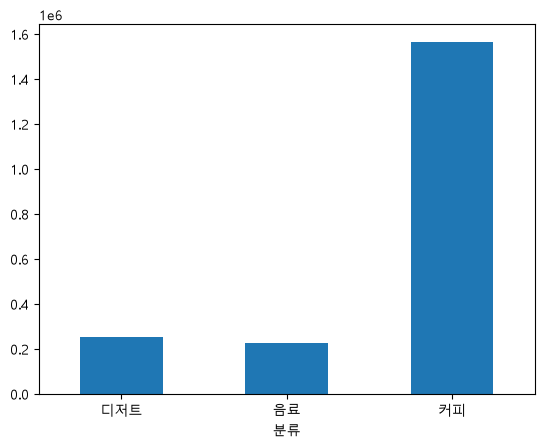

In [204]:
df7 = df.groupby('분류')['매출'].sum()
df7.plot(kind='bar', rot=0)

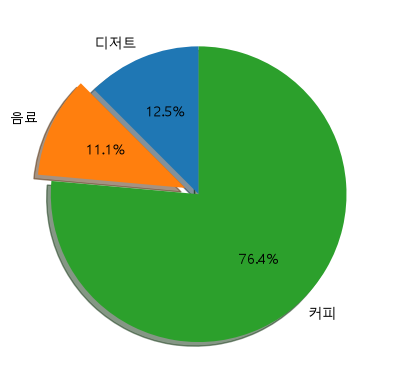

In [206]:
a = [0, 0.1, 0]
plt.pie(
    df7.values,
    labels=df7.index,
    autopct='%1.1f%%',
    startangle=90,
    shadow=True,
    explode=a,
)
plt.show()

## 확인문제
아래 빈 셀에 직접 코드를 작성해 보세요.

In [207]:
df

,날짜,지점,메뉴,분류,가격,판매수량,날씨,매출,판매등급,요일
0,2026-11-02,강남점,아메리카노,커피,4500,32,맑음,144000,인기,월
1,2026-11-02,강남점,카페라테,커피,5000,18,맑음,90000,보통,월
2,2026-11-02,강남점,치즈케이크,디저트,6500,7,맑음,45500,보통,월
3,2026-11-02,홍대점,아메리카노,커피,4300,41,맑음,176300,인기,월
4,2026-11-02,홍대점,자몽에이드,음료,5800,12,맑음,69600,보통,월
5,2026-11-03,강남점,아메리카노,커피,4500,28,흐림,126000,보통,화
6,2026-11-03,강남점,카페라테,커피,5000,21,흐림,105000,보통,화
7,2026-11-03,홍대점,카페라테,커피,4800,22,흐림,105600,보통,화
8,2026-11-03,홍대점,치즈케이크,디저트,6300,9,흐림,56700,보통,화
9,2026-11-03,홍대점,자몽에이드,음료,5800,8,흐림,46400,보통,화


**문제 1.** 요일별 판매 수량 합계를 월·화·수·목 순서로 선 그래프로 그리세요. 점을 표시하세요.

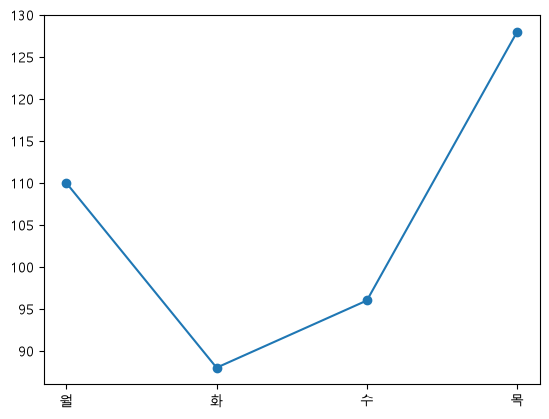

In [213]:
# 여기에 코드를 작성하세요
day_df = df.groupby('요일')['판매수량'].sum().reindex(['월', '화', '수', '목'])
plt.plot(day_df.index, day_df.values, marker='o')
plt.show()

**문제 2.** 지점별 총매출을 막대 그래프로 그리고, 막대 위에 매출액을 표시하세요.

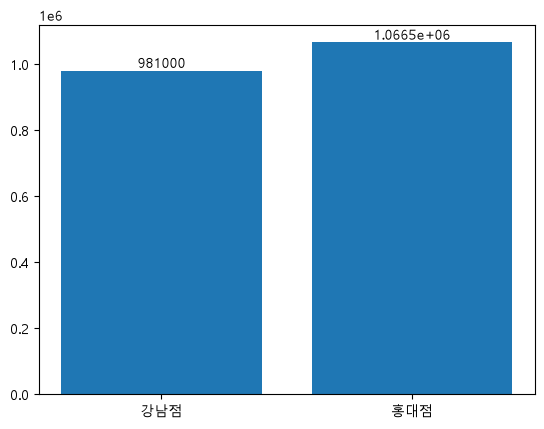

In [218]:
# 여기에 코드를 작성하세요
revenue_df = df.groupby('지점')['매출'].sum()
bars = plt.bar(revenue_df.index, revenue_df.values)
# plt.bar(revenue_df.index, revenue_df.values)
plt.bar_label(bars)
plt.show()

**문제 3.** 날씨별 평균 판매 수량을 가로 막대 그래프로 그리세요.

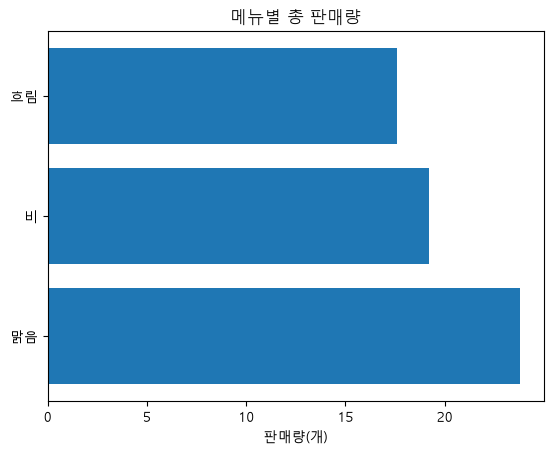

In [219]:
# 여기에 코드를 작성하세요
wether_df = df.groupby('날씨')['판매수량'].mean()
plt.barh(wether_df.index, wether_df.values)
plt.title('메뉴별 총 판매량')
plt.xlabel('판매량(개)')
plt.show()

**문제 4.** 가격(`가격`) 분포를 히스토그램으로 그리세요. (`bins=4`)

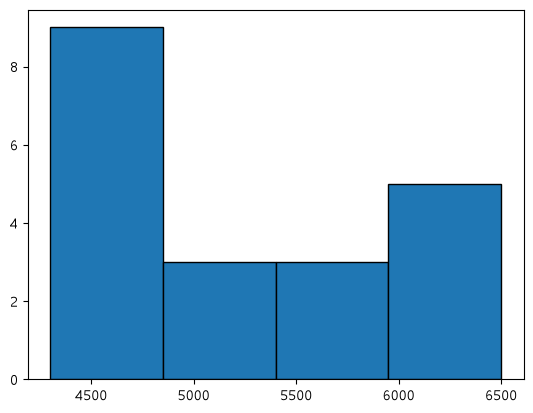

In [221]:
# 여기에 코드를 작성하세요
plt.hist(df['가격'], bins=4, edgecolor='black')
plt.show()

**문제 5.** 지점별 매출 비중을 파이 그래프로 그리고, 왜 이 경우에는 파이 그래프가 적절한지 한 문장으로 설명하세요.

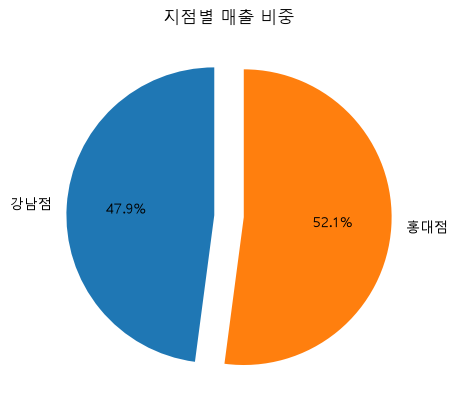

In [225]:
# 여기에 코드를 작성하세요
place_revenue_df = df.groupby('지점')['매출'].sum()
plt.pie(
    place_revenue_df.values,
    labels= place_revenue_df.index,
    autopct='%.1f%%',
    startangle=90,
    explode = [0.1] * len(place_revenue_df))
plt.title('지점별 매출 비중')
plt.show()

**문제 5 설명:** (파이 그래프가 적절한 이유를 한 문장으로 쓰세요)

직관적으로 한눈에 알아보기 쉬움